# Python · Kriging — `update`, `simulate`, `update_simulate`

**Idea.** Adding observations (`update`) and drawing conditional paths (`simulate`,
`update_simulate`) are shortcuts: they must give what the long way gives.

**Reference.** A model fitted from scratch on all the data, and Monte Carlo moments
against the predictive mean and covariance.

**Tags.** class: Kriging · topic: update, conditional simulation

Sequential use of a fitted model (sequential design, Bayesian optimization):

* `update(y_u, X_u, refit=False)` adds observations through a Cholesky
  (Schur complement) update, keeping θ; β and σ² are re-estimated (profiled)
  on the enlarged data. It must match a model built from scratch on all the
  data with the same θ (`optim="none"`, σ² and β estimated).
* `update(..., refit=True)` re-optimizes: it must match a fresh fit (up to the
  optimizer: warn-level).
* `simulate(nsim, seed, X)` draws conditional paths: their empirical mean and
  covariance must converge to `predict`'s mean and covariance; a seed makes
  them reproducible; at the design points they reproduce y.
* `update_simulate(y_u, X_u)` conditions paths already drawn on new data: the
  corrected paths must be distributed as fresh paths of the updated model.

Functions: Branin (2D), Hartmann 3 (3D), Hartmann 6 (6D).

In [1]:
# Setup for running this notebook outside the repository (Colab, Binder, a lone copy):
# nothing to do in the repository itself (CI, local runs). Otherwise the repository
# (datasets of data/, helpers of tools/python/gallery.py) is cloned and the released pylibkriging installed.
import importlib
import os
import subprocess
import sys
from pathlib import Path

if not Path("tools/known_issues.csv").is_file():
    if not Path("gallery/tools/known_issues.csv").is_file():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/libKriging/gallery"], check=True)
    os.chdir("gallery")
    try:
        import pylibkriging  # noqa: F401
    except ImportError:
        r = subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "pylibkriging"],
                           capture_output=True, text=True)
        if r.returncode != 0:
            raise RuntimeError(
                f"pylibkriging could not be installed for Python {sys.version_info.major}.{sys.version_info.minor} "
                "(PyPI has wheels for CPython 3.10 to 3.12 only). On Colab: Runtime > Change runtime version > "
                "2026.07 (Python 3.12), then run again.\n" + r.stderr[-500:])
        importlib.invalidate_caches()
sys.path.insert(0, str(Path("tools/python").resolve()))  # for "import gallery" (tools/python/gallery.py)
print("working directory:", os.getcwd())

working directory: /home/runner/work/gallery/gallery


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pylibkriging as lk

import gallery
from gallery import TESTS, design, compat

suite = gallery.Suite("update-simulate_Kriging_python")
print("pylibkriging", compat.version())


def pred(k, X, cov=False):
    m, s, c, *_ = k.predict(X, return_stdev=True, return_cov=cov)
    return np.ravel(m), np.ravel(s), np.asarray(c)


def fixed_params(k):
    return {"theta": np.asarray(k.theta()).reshape(1, -1), "is_theta_estim": False,
            "sigma2": float(k.sigma2()), "is_sigma2_estim": False}

pylibkriging 1.2.2


## `update` vs a fit from scratch

In [3]:
for fname, n0, nu in [("branin", 20, 5), ("hartmann3", 30, 10), ("hartmann6", 60, 20)]:
    tf = TESTS[fname]
    X, y, Xt, yt = design.dataset(tf, n0 + nu, n_test=300, seed=21)
    for trend in ["constant", "linear"]:
        case = f"{fname}/{trend}"
        k = lk.Kriging(y[:n0], X[:n0], "matern5_2", regmodel=trend)
        p = fixed_params(k)
        k.update(y[n0:], X[n0:], refit=False)
        ref = lk.Kriging(y, X, "matern5_2", regmodel=trend, optim="none",
                         parameters={"theta": p["theta"], "is_theta_estim": False})
        m, s, _ = pred(k, Xt)
        mr, sr, _ = pred(ref, Xt)
        suite.check_close(f"{case}: update(refit=False) mean == scratch fit, same theta", m, mr, rtol=1e-6,
                    atol=1e-8 * np.std(y))
        suite.check_close(f"{case}: update(refit=False) stdev == scratch fit, same theta", s, sr, rtol=1e-5,
                    atol=1e-8 * np.std(y))
        suite.check_close(f"{case}: update(refit=False) sigma2 == scratch fit sigma2", k.sigma2(), ref.sigma2(),
                    rtol=1e-8)
        suite.check_close(f"{case}: update(refit=False) keeps theta", np.ravel(k.theta()), np.ravel(p["theta"]),
                    rtol=0, atol=0)
        suite.check_true(f"{case}: model holds n0+nu points", np.asarray(k.X()).shape[0] == n0 + nu)
        # refit=True vs a fresh fit (same optimizer from the same data, possibly another start)
        k2 = lk.Kriging(y[:n0], X[:n0], "matern5_2", regmodel=trend)
        k2.update(y[n0:], X[n0:], refit=True)
        fresh = lk.Kriging(y, X, "matern5_2", regmodel=trend)
        suite.check_close(f"{case}: update(refit=True) LL == fresh fit LL", k2.logLikelihood(), fresh.logLikelihood(),
                    rtol=1e-3, severity="warn")

[WARN] hartmann3/linear: update(refit=True) LL == fresh fit LL: value=0.0191871 expected rtol 0.001, atol 0 


[WARN] hartmann6/constant: update(refit=True) LL == fresh fit LL: value=0.427575 expected rtol 0.001, atol 0 
[WARN] hartmann6/linear: update(refit=True) LL == fresh fit LL: value=0.219426 expected rtol 0.001, atol 0 


Several small updates in a row equal one update with all the points.

In [4]:
tf = TESTS["hartmann3"]
X, y, Xt, _ = design.dataset(tf, 40, n_test=200, seed=22)
ka = lk.Kriging(y[:20], X[:20], "matern5_2")
kb = lk.Kriging(y[:20], X[:20], "matern5_2")
for i in range(20, 40, 5):
    ka.update(y[i:i + 5], X[i:i + 5], refit=False)
kb.update(y[20:], X[20:], refit=False)
suite.check_close("4 updates of 5 == 1 update of 20 (mean)", pred(ka, Xt)[0], pred(kb, Xt)[0], rtol=1e-8, atol=1e-10)
suite.check_close("4 updates of 5 == 1 update of 20 (stdev)", pred(ka, Xt)[1], pred(kb, Xt)[1], rtol=1e-6, atol=1e-10)

True

## `simulate`: moments, seeds, conditioning

In [5]:
for fname, n in [("branin", 20), ("hartmann3", 30)]:
    tf = TESTS[fname]
    X, y, Xt, _ = design.dataset(tf, n, n_test=15, seed=23)
    k = lk.Kriging(y, X, "matern5_2")
    nsim = 5000
    S = np.asarray(k.simulate(nsim, 123, Xt))
    suite.check_true(f"{fname}: simulate shape (q, nsim)", S.shape == (len(Xt), nsim), detail=str(S.shape))
    m, s, c = pred(k, Xt, cov=True)
    z = (S.mean(axis=1) - m) / (s / np.sqrt(nsim))
    suite.check_less(f"{fname}: empirical mean of paths vs predict (max |z|)", np.max(np.abs(z)), 5.0)
    rel = np.linalg.norm(np.cov(S) - c) / np.linalg.norm(c)
    suite.check_less(f"{fname}: empirical covariance of paths vs predict (rel. Frobenius)", rel, 0.1)
    S2 = np.asarray(k.simulate(nsim, 123, Xt))
    suite.check_close(f"{fname}: same seed, same paths", S2, S, rtol=0, atol=0)
    S3 = np.asarray(k.simulate(nsim, 124, Xt))
    suite.check_true(f"{fname}: another seed, other paths", not np.allclose(S3, S))
    Sx = np.asarray(k.simulate(20, 1, X[:5]))
    # up to the numerical jitter added to the conditional covariance (relative to the prior sd)
    suite.check_close(f"{fname}: paths reproduce y at the design points", Sx, np.tile(y[:5, None], (1, 20)),
                rtol=0, atol=1e-4 * np.sqrt(k.sigma2()))

## `update_simulate`: paths conditioned on new data

Paths drawn with `will_update=True`, then corrected by `update_simulate(y_u,
X_u)`, must have the moments of the model updated with (X_u, y_u).

In [6]:
tf = TESTS["branin"]
X, y, Xt, _ = design.dataset(tf, 25, n_test=12, seed=24)
n0 = 20
k = lk.Kriging(y[:n0], X[:n0], "matern5_2")
p = fixed_params(k)
nsim = 5000
with suite.check_runs("update_simulate runs"):
    k.simulate(nsim, 7, Xt, will_update=True)
    U = np.asarray(k.update_simulate(y[n0:], X[n0:]))
    # paths drawn under (theta, sigma2) of the first model, then conditioned on all the data
    ref = lk.Kriging(y, X, "matern5_2", optim="none", parameters=p)
    m, s, c = pred(ref, Xt, cov=True)
    z = (U.mean(axis=1) - m) / (s / np.sqrt(nsim))
    suite.check_less("update_simulate: mean of corrected paths vs updated model (max |z|)", np.max(np.abs(z)), 5.0)
    rel = np.linalg.norm(np.cov(U) - c) / np.linalg.norm(c)
    suite.check_less("update_simulate: covariance vs updated model (rel. Frobenius)", rel, 0.1)

## In pictures: Forrester, 6 points, then 2 more

Conditional paths of the 6-point model (left), the same paths corrected by
`update_simulate` with 2 new observations (right): they now go through the new
points, without redrawing them.

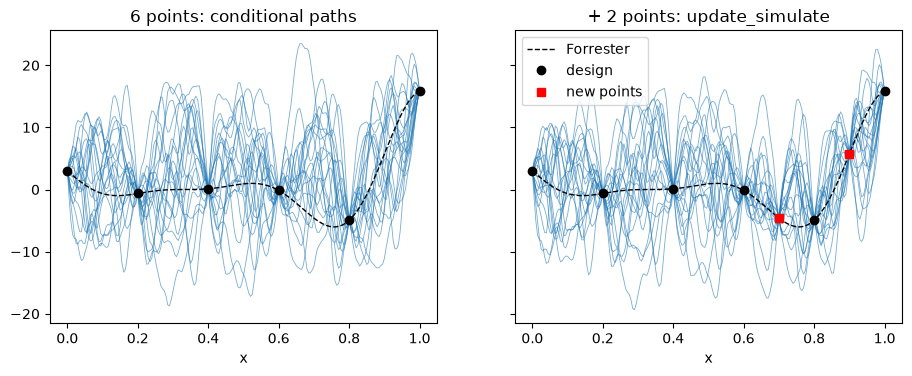

In [7]:
tf = TESTS["forrester"]
X = np.array([[0.0], [0.2], [0.4], [0.6], [0.8], [1.0]]); y = tf.unit(X)
Xu = np.array([[0.7], [0.9]]); yu = tf.unit(Xu)
G = np.linspace(0, 1, 201).reshape(-1, 1)
k = lk.Kriging(y, X, "matern5_2")
P = np.asarray(k.simulate(20, 3, G, will_update=True))
PU = np.asarray(k.update_simulate(yu, Xu))
suite.check_less("update_simulate: corrected paths go through the new points (max |path - y_u| / sd(y))",
           np.max(np.abs(PU[[140, 180], :] - yu[:, None])) / np.std(y), 1e-3)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, paths, title in [(axes[0], P, "6 points: conditional paths"), (axes[1], PU, "+ 2 points: update_simulate")]:
    ax.plot(G, paths, color="tab:blue", lw=.6, alpha=.6)
    ax.plot(G, tf.unit(G), "k--", lw=1, label="Forrester")
    ax.plot(X, y, "ko", label="design")
    ax.set_title(title); ax.set_xlabel("x")
axes[1].plot(Xu, yu, "rs", label="new points"); axes[1].legend(); plt.show()

## Summary

The metrics of this notebook, the number of checks per status, and every check that
did not pass (FAIL: error-level, fails the run; WARN: warn-level; KNOWN: listed in
`tools/known_issues.csv`, with its issue; SKIP: feature absent from the installed version).
All of them are also written to `results/update-simulate_Kriging_python.checks.csv` and `.metrics.csv`.

In [8]:
suite.summary()

54 checks: PASS 51, FAIL 0, WARN 3, KNOWN 0, SKIP 0


,status,severity,check,value,expected,detail
0,WARN,warn,hartmann3/linear: update(refit=True) LL == fre...,0.0191871,"rtol 0.001, atol 0",
1,WARN,warn,hartmann6/constant: update(refit=True) LL == f...,0.427575,"rtol 0.001, atol 0",
2,WARN,warn,hartmann6/linear: update(refit=True) LL == fre...,0.219426,"rtol 0.001, atol 0",


In [9]:
suite.finalize()

update-simulate_Kriging_python: PASS 51, FAIL 0, WARN 3, KNOWN 0, SKIP 0


{'PASS': 51, 'FAIL': 0, 'WARN': 3, 'KNOWN': 0, 'SKIP': 0}